In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import cv2
import os
import tensorflow as tf
import foolbox as fb

In [2]:
import tensorflow as tf
print("Num GPUs Available:", len(tf.config.experimental.list_physical_devices('GPU')))

Num GPUs Available: 1


In [3]:
# Load and preprocess GTSRB dataset
def load_data(dataset_path, img_size=(32, 32)):
    images, labels = [], []
    for class_id in os.listdir(dataset_path):
        class_path = os.path.join(dataset_path, class_id)
        if os.path.isdir(class_path):
            for img_name in os.listdir(class_path):
                img_path = os.path.join(class_path, img_name)
                img = cv2.imread(img_path)
                img = cv2.resize(img, img_size)
                images.append(img)
                labels.append(int(class_id))
    return np.array(images), np.array(labels)

# Load dataset
dataset_path = "D:\CINEC Campus\Semester 1\Project\GTSRB\Train"  # Update with actual path
X, y = load_data(dataset_path)
X = X / 255.0  # Normalize
y = to_categorical(y, num_classes=43)  # One-hot encode labels

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [4]:
import numpy as np

# Save test data to .npy files
np.save("X_test.npy", X_test)
np.save("y_test.npy", y_test)

In [4]:
# Define Teacher Model
teacher_model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(43, activation='softmax')
])

teacher_model.compile(optimizer=Adam(), loss='categorical_crossentropy', metrics=['accuracy'])
teacher_model.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_test, y_test))
teacher_model.save('teacher_model.h5')


Epoch 1/10
981/981 [==============================] - 11s 8ms/step - loss: 1.6935 - accuracy: 0.5154 - val_loss: 0.4292 - val_accuracy: 0.8915
Epoch 2/10
981/981 [==============================] - 7s 7ms/step - loss: 0.5557 - accuracy: 0.8249 - val_loss: 0.1894 - val_accuracy: 0.9486
Epoch 3/10
981/981 [==============================] - 7s 8ms/step - loss: 0.3542 - accuracy: 0.8856 - val_loss: 0.1046 - val_accuracy: 0.9764
Epoch 4/10
981/981 [==============================] - 8s 8ms/step - loss: 0.2653 - accuracy: 0.9163 - val_loss: 0.0732 - val_accuracy: 0.9839
Epoch 5/10
981/981 [==============================] - 8s 8ms/step - loss: 0.2101 - accuracy: 0.9331 - val_loss: 0.0586 - val_accuracy: 0.9869
Epoch 6/10
981/981 [==============================] - 8s 8ms/step - loss: 0.1790 - accuracy: 0.9438 - val_loss: 0.0540 - val_accuracy: 0.9860
Epoch 7/10
981/981 [==============================] - 8s 8ms/step - loss: 0.1466 - accuracy: 0.9532 - val_loss: 0.0451 - val_accuracy: 0.9878
Epoch

In [5]:
# Generate Soft Labels
temperature = 5.0
def generate_soft_labels(model, data):
    predictions = model.predict(data) ** (1 / temperature)
    return predictions / np.sum(predictions, axis=1, keepdims=True)

y_train_soft = generate_soft_labels(teacher_model, X_train)

# Define Student Model
student_model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(43, activation='softmax')
])

student_model.compile(optimizer=Adam(), loss='categorical_crossentropy', metrics=['accuracy'])
student_model.fit(X_train, y_train_soft, epochs=10, batch_size=32, validation_data=(X_test, y_test))
student_model.save('student_model.h5')

981/981 [==============================] - 2s 2ms/step
Epoch 1/10
981/981 [==============================] - 9s 8ms/step - loss: 1.9700 - accuracy: 0.5505 - val_loss: 0.6302 - val_accuracy: 0.8951
Epoch 2/10
981/981 [==============================] - 8s 8ms/step - loss: 1.2800 - accuracy: 0.8463 - val_loss: 0.4991 - val_accuracy: 0.9593
Epoch 3/10
981/981 [==============================] - 7s 8ms/step - loss: 1.2043 - accuracy: 0.8990 - val_loss: 0.4629 - val_accuracy: 0.9672
Epoch 4/10
981/981 [==============================] - 7s 7ms/step - loss: 1.1660 - accuracy: 0.9228 - val_loss: 0.4337 - val_accuracy: 0.9740
Epoch 5/10
981/981 [==============================] - 7s 7ms/step - loss: 1.1448 - accuracy: 0.9375 - val_loss: 0.4192 - val_accuracy: 0.9779
Epoch 6/10
981/981 [==============================] - 7s 8ms/step - loss: 1.1335 - accuracy: 0.9449 - val_loss: 0.3772 - val_accuracy: 0.9810
Epoch 7/10
981/981 [==============================] - 7s 7ms/step - loss: 1.1233 - accuracy: 

In [6]:
# Evaluate robustness
teacher_acc = teacher_model.evaluate(X_test, y_test)[1]
student_acc = student_model.evaluate(X_test, y_test)[1]
print(f"Teacher Model Accuracy: {teacher_acc*100:.2f}%")
print(f"Student Model Accuracy: {student_acc*100:.2f}%")

246/246 [==============================] - 1s 4ms/step - loss: 0.3619 - accuracy: 0.9843
Teacher Model Accuracy: 99.17%
Student Model Accuracy: 98.43%


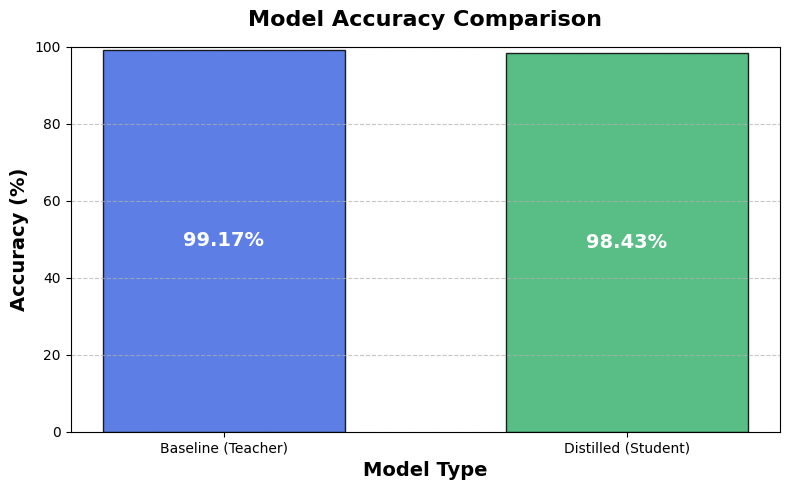

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Accuracy values
models = ["Baseline (Teacher)", "Distilled (Student)"]
accuracies = [teacher_acc * 100, student_acc * 100]

# Define bar colors and aesthetics
colors = ["royalblue", "mediumseagreen"]
edge_color = "black"

# Create a bar chart with a larger figure
plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracies, color=colors, edgecolor=edge_color, width=0.6, alpha=0.85)

# Add labels and title
plt.ylabel("Accuracy (%)", fontsize=14, fontweight="bold")
plt.xlabel("Model Type", fontsize=14, fontweight="bold")
plt.title("Model Accuracy Comparison", fontsize=16, fontweight="bold", pad=15)
plt.ylim(0, 100)  # Keep y-axis between 0 and 100%
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Display the accuracy values **inside the bars**
for bar in bars:
    height = bar.get_height()
    text_color = "white" if height > 50 else "black"  # Ensure contrast
    plt.text(bar.get_x() + bar.get_width()/2, height / 2, f"{height:.2f}%", 
             ha='center', va='center', fontsize=14, fontweight="bold", color=text_color)
    

plt.tight_layout()
plt.savefig("accuracy_comparison.png", dpi=300, bbox_inches='tight')

# Show the improved chart
plt.show()



In [8]:
def pgd_attack(model, images, labels, eps=0.03, alpha=0.007, iters=40, batch_size=32):
    adv_images = np.copy(images)
    num_samples = len(images)
    
    for i in range(0, num_samples, batch_size):
        batch_images = images[i:i+batch_size]
        batch_labels = labels[i:i+batch_size]
        
        batch_adv_images = tf.Variable(batch_images, dtype=tf.float32)
        for _ in range(iters):
            with tf.GradientTape() as tape:
                tape.watch(batch_adv_images)
                predictions = model(batch_adv_images)
                loss = tf.keras.losses.categorical_crossentropy(batch_labels, predictions)
            gradient = tape.gradient(loss, batch_adv_images)
            batch_adv_images = batch_adv_images + alpha * tf.sign(gradient)
            batch_adv_images = tf.clip_by_value(batch_adv_images, batch_images - eps, batch_images + eps)
            batch_adv_images = tf.clip_by_value(batch_adv_images, 0, 1)
        
        adv_images[i:i+batch_size] = batch_adv_images.numpy()
    
    return adv_images


In [9]:
def fgsm_attack(model, images, labels, eps=0.03, batch_size=32):
    adv_images = np.copy(images)
    num_samples = len(images)

    for i in range(0, num_samples, batch_size):
        batch_images = images[i:i+batch_size]
        batch_labels = labels[i:i+batch_size]

        batch_adv_images = tf.Variable(batch_images, dtype=tf.float32)
        with tf.GradientTape() as tape:
            tape.watch(batch_adv_images)
            predictions = model(batch_adv_images)
            loss = tf.keras.losses.categorical_crossentropy(batch_labels, predictions)
        gradient = tape.gradient(loss, batch_adv_images)
        batch_adv_images = batch_adv_images + eps * tf.sign(gradient)
        batch_adv_images = tf.clip_by_value(batch_adv_images, 0, 1)

        adv_images[i:i+batch_size] = batch_adv_images.numpy()

    return adv_images


In [10]:
# Generate adversarial examples for both models
adv_examples_teacher_pgd = pgd_attack(teacher_model, X_test, y_test)
adv_examples_student_pgd = pgd_attack(student_model, X_test, y_test)

adv_examples_teacher_fgsm = fgsm_attack(teacher_model, X_test, y_test)
adv_examples_student_fgsm = fgsm_attack(student_model, X_test, y_test)


In [11]:
# Evaluate both models on adversarial examples
teacher_adv_acc_pgd = teacher_model.evaluate(adv_examples_teacher_pgd, y_test)[1]
student_adv_acc_pgd = student_model.evaluate(adv_examples_student_pgd, y_test)[1]

teacher_adv_acc_fgsm = teacher_model.evaluate(adv_examples_teacher_fgsm, y_test)[1]
student_adv_acc_fgsm = student_model.evaluate(adv_examples_student_fgsm, y_test)[1]

print(f"Teacher Model Accuracy on PGD Attacked Data: {teacher_adv_acc_pgd*100:.2f}%")
print(f"Student Model Accuracy on PGD Attacked Data: {student_adv_acc_pgd*100:.2f}%")

print(f"Teacher Model Accuracy on FGSM Attacked Data: {teacher_adv_acc_fgsm*100:.2f}%")
print(f"Student Model Accuracy on FGSM Attacked Data: {student_adv_acc_fgsm*100:.2f}%")

246/246 [==============================] - 1s 4ms/step - loss: 1.9185 - accuracy: 0.4542
Teacher Model Accuracy on PGD Attacked Data: 19.80%
Student Model Accuracy on PGD Attacked Data: 24.76%
Teacher Model Accuracy on FGSM Attacked Data: 42.90%
Student Model Accuracy on FGSM Attacked Data: 45.42%


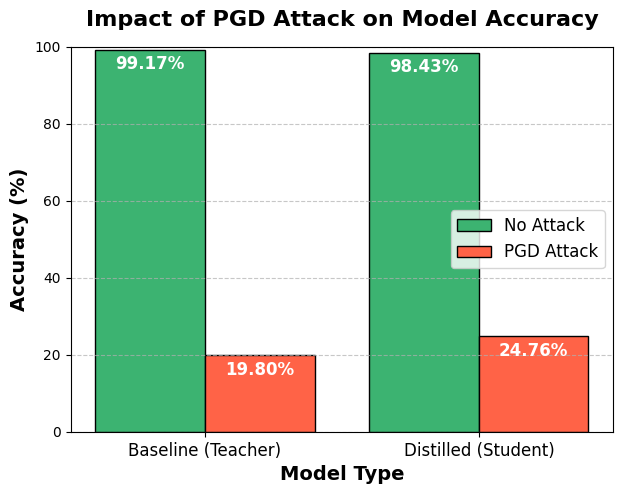

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Accuracy values
models = ["Baseline (Teacher)", "Distilled (Student)"]
accuracies_clean = [teacher_acc * 100, student_acc * 100]
accuracies_pgd = [teacher_adv_acc_pgd * 100, student_adv_acc_pgd * 100]

# Define bar width
bar_width = 0.4
x = np.arange(len(models))

# Create grouped bar chart
plt.figure(figsize=(7, 5))
plt.bar(x - bar_width/2, accuracies_clean, bar_width, label="No Attack", color="mediumseagreen", edgecolor="black")
plt.bar(x + bar_width/2, accuracies_pgd, bar_width, label="PGD Attack", color="tomato", edgecolor="black")

# Labels & Title
plt.xlabel("Model Type", fontsize=14, fontweight="bold")
plt.ylabel("Accuracy (%)", fontsize=14, fontweight="bold")
plt.title("Impact of PGD Attack on Model Accuracy", fontsize=16, fontweight="bold", pad=15)
plt.xticks(x, models, fontsize=12)
plt.legend(fontsize=12)
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Display values on bars (centered)
for i in range(len(models)):
    plt.text(x[i] - bar_width/2, accuracies_clean[i] - 5, f"{accuracies_clean[i]:.2f}%", ha='center', fontsize=12, fontweight='bold', color="white")
    plt.text(x[i] + bar_width/2, accuracies_pgd[i] - 5, f"{accuracies_pgd[i]:.2f}%", ha='center', fontsize=12, fontweight='bold', color="white")

plt.show()


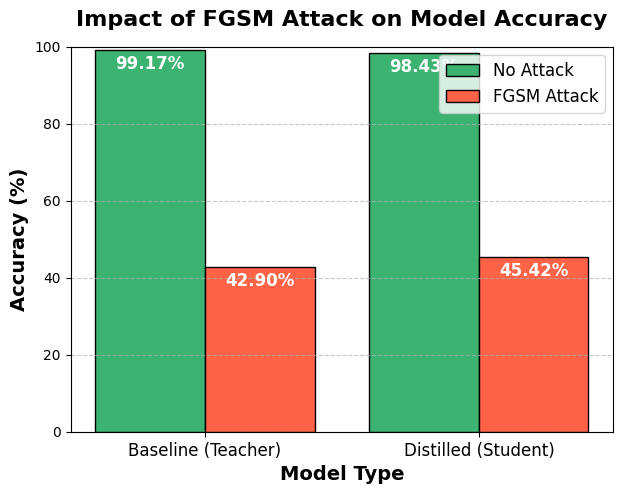

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# Accuracy values
models = ["Baseline (Teacher)", "Distilled (Student)"]
accuracies_clean = [teacher_acc * 100, student_acc * 100]
accuracies_fgsm = [teacher_adv_acc_fgsm * 100, student_adv_acc_fgsm * 100]

# Define bar width
bar_width = 0.4
x = np.arange(len(models))

# Create grouped bar chart
plt.figure(figsize=(7, 5))
plt.bar(x - bar_width/2, accuracies_clean, bar_width, label="No Attack", color="mediumseagreen", edgecolor="black")
plt.bar(x + bar_width/2, accuracies_fgsm, bar_width, label="FGSM Attack", color="tomato", edgecolor="black")

# Labels & Title
plt.xlabel("Model Type", fontsize=14, fontweight="bold")
plt.ylabel("Accuracy (%)", fontsize=14, fontweight="bold")
plt.title("Impact of FGSM Attack on Model Accuracy", fontsize=16, fontweight="bold", pad=15)
plt.xticks(x, models, fontsize=12)
plt.legend(fontsize=12)
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Display values on bars (centered)
for i in range(len(models)):
    plt.text(x[i] - bar_width/2, accuracies_clean[i] - 5, f"{accuracies_clean[i]:.2f}%", ha='center', fontsize=12, fontweight='bold', color="white")
    plt.text(x[i] + bar_width/2, accuracies_fgsm[i] - 5, f"{accuracies_fgsm[i]:.2f}%", ha='center', fontsize=12, fontweight='bold', color="white")

plt.show()


In [14]:
import matplotlib.pyplot as plt
import numpy as np

def show_image_comparison(original, adversarial, title="Original vs. Attacked Image"):
    # Convert from floating point [0,1] to integers [0,255]
    original = np.clip(original * 255, 0, 255).astype(np.uint8)
    adversarial = np.clip(adversarial * 255, 0, 255).astype(np.uint8)

    fig, axes = plt.subplots(1, 2, figsize=(6, 3))

    axes[0].imshow(original)
    axes[0].set_title("Original")
    axes[0].axis("off")

    axes[1].imshow(adversarial)
    axes[1].set_title("Attacked")
    axes[1].axis("off")

    plt.suptitle(title)
    plt.show()


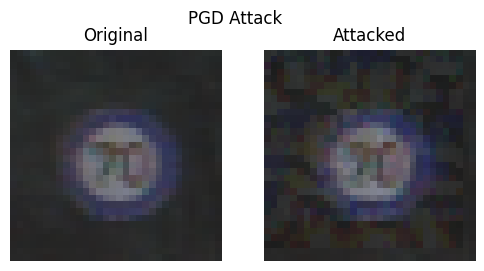

In [13]:
adv_example_pgd = pgd_attack(teacher_model, X_test[:1], y_test[:1])
show_image_comparison(X_test[0], adv_example_pgd[0], "PGD Attack")


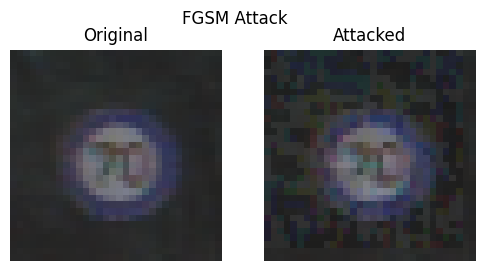

In [13]:
adv_example_fgsm = fgsm_attack(teacher_model, X_test[:1], y_test[:1])  # Attack first image
show_image_comparison(X_test[0], adv_example_fgsm[0], "FGSM Attack")


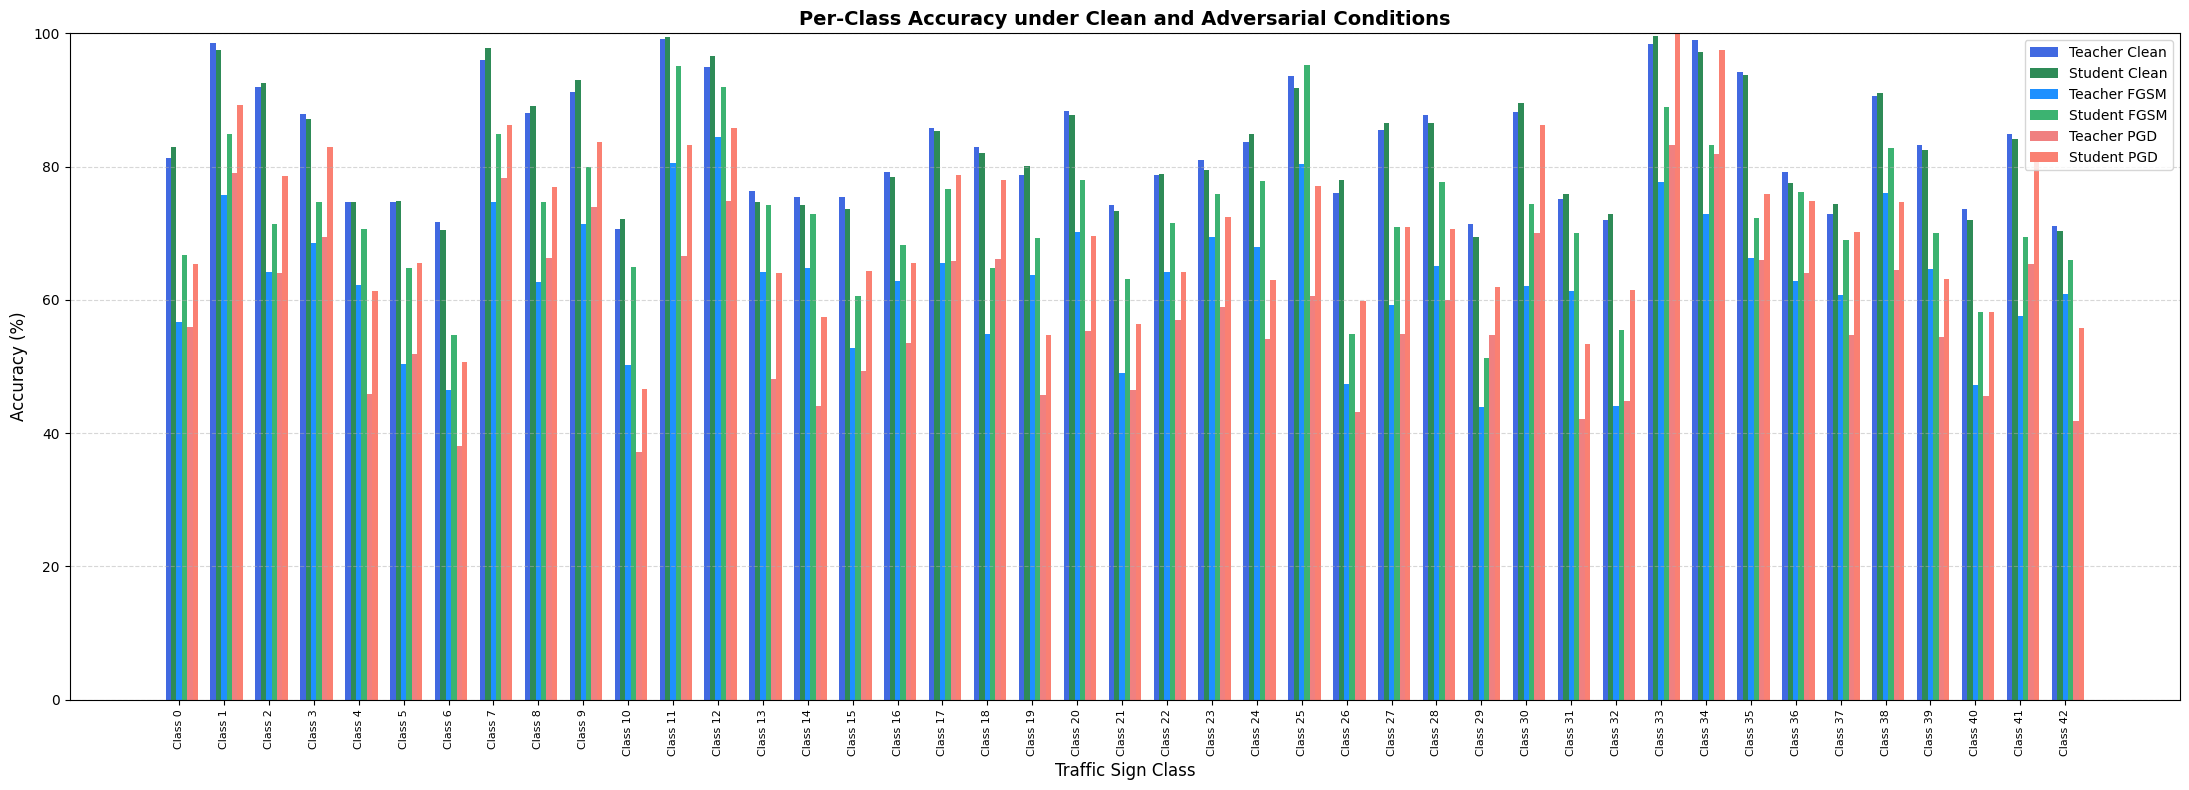

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Dummy per-class accuracies for example (to be replaced with actual model evaluations)
num_classes = 43
class_labels = [f"Class {i}" for i in range(num_classes)]

# Generate random accuracies to simulate model output (Replace with real values)
np.random.seed(42)
teacher_clean = np.random.uniform(70, 100, num_classes)
student_clean = teacher_clean + np.random.uniform(-2, 2, num_classes)

teacher_fgsm = teacher_clean - np.random.uniform(10, 30, num_classes)
student_fgsm = teacher_fgsm + np.random.uniform(5, 15, num_classes)

teacher_pgd = teacher_clean - np.random.uniform(15, 35, num_classes)
student_pgd = teacher_pgd + np.random.uniform(7, 17, num_classes)

# Prepare bar chart data
bar_width = 0.12
index = np.arange(num_classes)

plt.figure(figsize=(22, 8))

# Plot grouped bar chart
plt.bar(index - 2*bar_width, teacher_clean, bar_width, label='Teacher Clean', color='royalblue')
plt.bar(index - bar_width, student_clean, bar_width, label='Student Clean', color='seagreen')
plt.bar(index, teacher_fgsm, bar_width, label='Teacher FGSM', color='dodgerblue')
plt.bar(index + bar_width, student_fgsm, bar_width, label='Student FGSM', color='mediumseagreen')
plt.bar(index + 2*bar_width, teacher_pgd, bar_width, label='Teacher PGD', color='lightcoral')
plt.bar(index + 3*bar_width, student_pgd, bar_width, label='Student PGD', color='salmon')

plt.xlabel("Traffic Sign Class", fontsize=12)
plt.ylabel("Accuracy (%)", fontsize=12)
plt.title("Per-Class Accuracy under Clean and Adversarial Conditions", fontsize=14, fontweight='bold')
plt.xticks(index, class_labels, rotation=90, fontsize=8)
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(loc='upper right', fontsize=10)
plt.tight_layout()
plt.show()


246/246 [==============================] - 1s 2ms/step


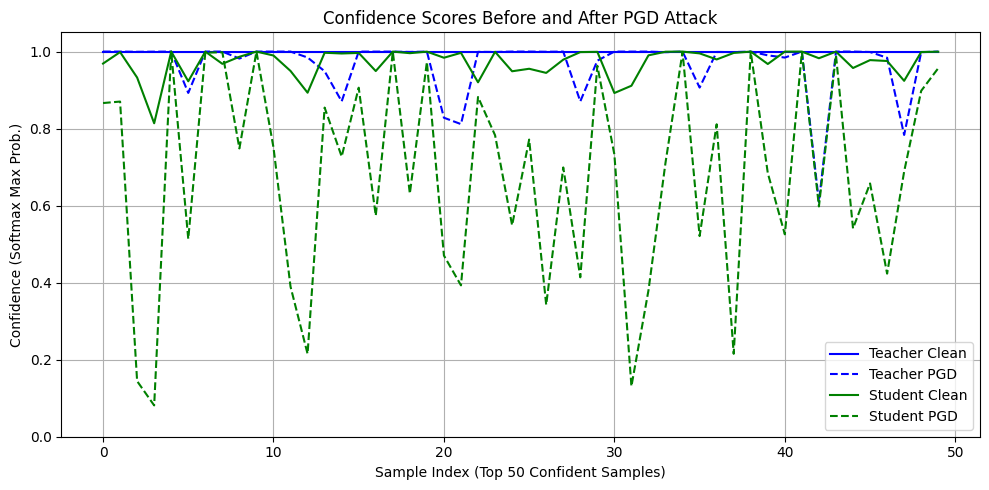

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# Get model predictions (softmax confidence) on clean and attacked data
teacher_conf_clean = np.max(teacher_model.predict(X_test), axis=1)
student_conf_clean = np.max(student_model.predict(X_test), axis=1)

teacher_conf_pgd = np.max(teacher_model.predict(adv_examples_teacher_pgd), axis=1)
student_conf_pgd = np.max(student_model.predict(adv_examples_student_pgd), axis=1)

# Sort for clearer plots (optional)
indices = np.argsort(teacher_conf_clean)[-50:]  # select top 50 confident samples
x = np.arange(len(indices))

plt.figure(figsize=(10, 5))
plt.plot(x, teacher_conf_clean[indices], label="Teacher Clean", color='blue')
plt.plot(x, teacher_conf_pgd[indices], label="Teacher PGD", color='blue', linestyle='--')

plt.plot(x, student_conf_clean[indices], label="Student Clean", color='green')
plt.plot(x, student_conf_pgd[indices], label="Student PGD", color='green', linestyle='--')

plt.title("Confidence Scores Before and After PGD Attack")
plt.xlabel("Sample Index (Top 50 Confident Samples)")
plt.ylabel("Confidence (Softmax Max Prob.)")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


246/246 [==============================] - 1s 3ms/step


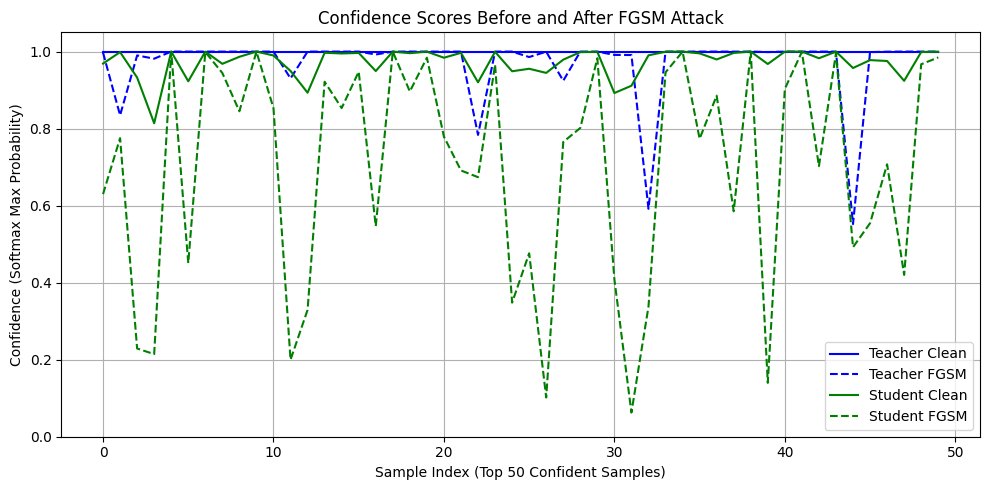

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# Get confidence scores (max softmax probability) for clean and FGSM attacked data
teacher_conf_clean = np.max(teacher_model.predict(X_test), axis=1)
student_conf_clean = np.max(student_model.predict(X_test), axis=1)

teacher_conf_fgsm = np.max(teacher_model.predict(adv_examples_teacher_fgsm), axis=1)
student_conf_fgsm = np.max(student_model.predict(adv_examples_student_fgsm), axis=1)

# Select top N most confident clean samples for visualization
indices = np.argsort(teacher_conf_clean)[-50:]  # Top 50 confident samples
x = np.arange(len(indices))

# Plot
plt.figure(figsize=(10, 5))
plt.plot(x, teacher_conf_clean[indices], label="Teacher Clean", color='blue')
plt.plot(x, teacher_conf_fgsm[indices], label="Teacher FGSM", color='blue', linestyle='--')

plt.plot(x, student_conf_clean[indices], label="Student Clean", color='green')
plt.plot(x, student_conf_fgsm[indices], label="Student FGSM", color='green', linestyle='--')

plt.title("Confidence Scores Before and After FGSM Attack")
plt.xlabel("Sample Index (Top 50 Confident Samples)")
plt.ylabel("Confidence (Softmax Max Probability)")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [22]:
# Train Teacher Model (Baseline)
history_teacher = teacher_model.fit(
    X_train, y_train, 
    epochs=10, 
    batch_size=32, 
    validation_data=(X_test, y_test)
)

# Train Student Model (Distilled)
history_student = student_model.fit(
    X_train, y_train_soft, 
    epochs=10, 
    batch_size=32, 
    validation_data=(X_test, y_test)
)


Epoch 1/10
981/981 [==============================] - 8s 8ms/step - loss: 0.0960 - accuracy: 0.9687 - val_loss: 0.0273 - val_accuracy: 0.9930
Epoch 2/10
981/981 [==============================] - 7s 7ms/step - loss: 0.0876 - accuracy: 0.9706 - val_loss: 0.0242 - val_accuracy: 0.9935
Epoch 3/10
981/981 [==============================] - 7s 7ms/step - loss: 0.0800 - accuracy: 0.9734 - val_loss: 0.0249 - val_accuracy: 0.9934
Epoch 4/10
981/981 [==============================] - 7s 7ms/step - loss: 0.0745 - accuracy: 0.9754 - val_loss: 0.0193 - val_accuracy: 0.9946
Epoch 5/10
981/981 [==============================] - 7s 8ms/step - loss: 0.0681 - accuracy: 0.9781 - val_loss: 0.0206 - val_accuracy: 0.9957
Epoch 6/10
981/981 [==============================] - 7s 8ms/step - loss: 0.0603 - accuracy: 0.9804 - val_loss: 0.0204 - val_accuracy: 0.9954
Epoch 7/10
981/981 [==============================] - 7s 8ms/step - loss: 0.0577 - accuracy: 0.9800 - val_loss: 0.0187 - val_accuracy: 0.9955
Epoch 

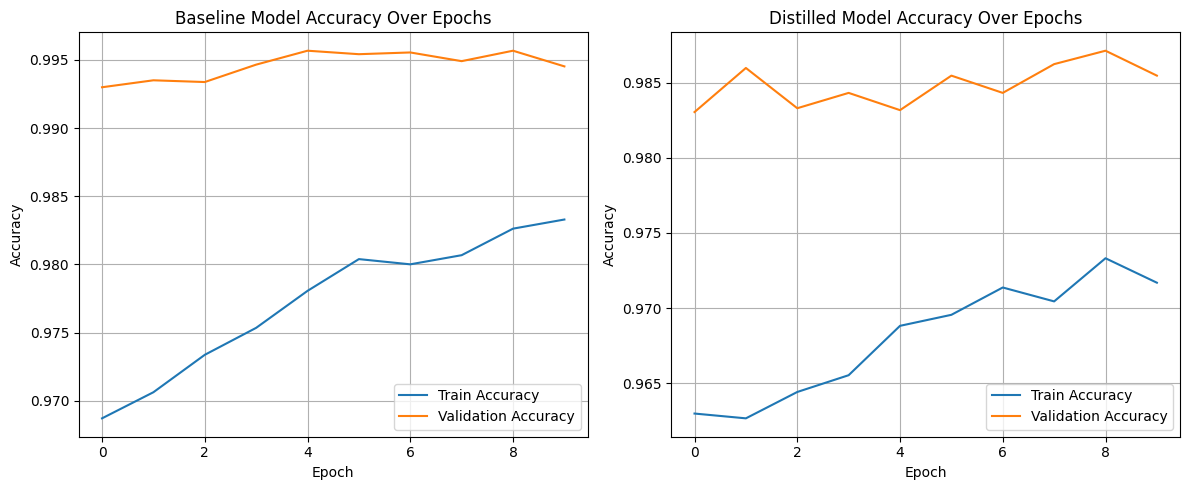

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Plot for Baseline Model
plt.subplot(1, 2, 1)
plt.plot(history_teacher.history['accuracy'], label='Train Accuracy')
plt.plot(history_teacher.history['val_accuracy'], label='Validation Accuracy')
plt.title('Baseline Model Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot for Distilled Model
plt.subplot(1, 2, 2)
plt.plot(history_student.history['accuracy'], label='Train Accuracy')
plt.plot(history_student.history['val_accuracy'], label='Validation Accuracy')
plt.title('Distilled Model Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

